# Native FastReso `*_Fj.out` vs `runcascade`: the small fixtures

Same method as `compare_fjout_runcascade.ipynb` — run upstream FastReso's own
driver, read its native `*_Fj.out`, project, compare against `runcascade` — but
pointed at the four hand-written fixtures instead of a trimmed physical list.

Each fixture isolates one mechanism, so when the realistic comparison drifts
this tells you *which part* moved:

| fixture | contents | tests |
|---|---|---|
| `rho_only.dat` | `rho0 -> pi+ pi-` | two-body decay |
| `omega_only.dat` | `omega -> pi+ pi- pi0` | three-body decay |
| `small_thermal.dat` | both of the above | superposition |
| `rho_chain.dat` | `rho(1700) -> rho0 pi- pi+`, `rho0 -> pi+ pi-` | two-step feed-down |

Only `pi+` is comparable: `run_fastreso_azyhydro.cpp` hard-codes
`pdg[] = {211, 321, 2212, 3122, 3312, 3334}` and the others do not appear in
these fixtures. Section 4 shows why that matters more than it sounds.

Each fixture is five species, so the whole notebook runs in seconds rather than
the ~90 s the realistic list needs.

## 1. Setup

In [2]:
using Printf, Statistics

# Notebook-only dependencies. They are installed into the shared default
# environment rather than the repository's Project.toml, which stays a
# description of what the *library* needs. The default environment is on
# LOAD_PATH, so these import fine while --project=Fast_reso2 is active.
using Pkg
let project = Base.active_project()
    for name in ("QuadGK", "Interpolations", "PyPlot")
        Base.find_package(name) === nothing || continue
        @info "installing $name into the default environment (not Project.toml)"
        Pkg.activate(); Pkg.add(name); Pkg.activate(project)
    end
end
using QuadGK: quadgk
using Interpolations: interpolate, extrapolate, Gridded, Linear, Flat
using PyPlot

REPO = let dir = pwd()
    while !isfile(joinpath(dir, "CascadeTables.jl")) && dir != dirname(dir)
        dir = dirname(dir)
    end
    dir
end
BENCH = joinpath(REPO, "benchmarks", "fastreso_crosscheck")
OUT = joinpath(BENCH, "output");  mkpath(OUT)

# Guarded: re-running this cell would otherwise `include` the module a second
# time, and names exported by both the stale and fresh copy become ambiguous
# ("UndefVarError: `nbody` not defined in `Main`"). To pick up edits to the
# .jl files, restart the kernel.
isdefined(Main, :CascadeTables) || include(joinpath(REPO, "CascadeTables.jl"))
using .CascadeTables

function plot_params(; gui = false, pHeight = 2.3)
    close("all")
    pygui(gui)
    rc("text", usetex = "true")
    rc("font", family = "serif")
    rc("font", size = 12)
    rc("xtick", labelsize = 12)
    rc("ytick", labelsize = 12)
    rc("lines", markersize = 1)
    rc("legend", fontsize = 10)
    rc("axes", titlesize = 12)
    rc("axes", titlepad = 10)
    return nothing
end
pHeight = 2.3
pWidth = 1.3333333 * pHeight
plot_params()

FASTRESO_DIR = get(ENV, "FASTRESO_DIR", joinpath(homedir(), "FastReso"))
DRIVER = joinpath(FASTRESO_DIR, "build", "run_fastreso_azyhydro.exe")

@printf("repo    %s\n", REPO)
@printf("driver  %s\n", isfile(DRIVER) ? DRIVER : "MISSING -- build FastReso, see README")

repo    /Users/eduardogrossi/Fast_reso2
driver  /Users/eduardogrossi/FastReso/build/run_fastreso_azyhydro.exe


## 2. Configuration

`T = 0.145 GeV` is fixed inside `run_fastreso_azyhydro.cpp` and cannot be passed
in.

`GRID` must extend well past `PMAX`: stopping at 3.5 GeV while comparing to 3.0
truncates the parents feeding high-`pT` daughters and inflates the feed-down
error by three orders of magnitude.

In [3]:
FIXTURES = ["rho_only.dat", "omega_only.dat", "small_thermal.dat", "rho_chain.dat"]
OBSERVED = 211                     # the only PDG both the driver and these fixtures share

TEMPERATURE = 0.145                # fixed inside run_fastreso_azyhydro.cpp
ORDERS = (nq = 128, nθ = 32, nµ = 32, nσ = 16, nma = 16)
GRID = range(0.0001, 8.0, length = 401)
ETAMAX = 5.0                       # TKernel's fixed |eta| window
QUAD_RTOL = 1e-10
PMIN, PMAX = 0.1, 3.0

momenta = collect(GRID)
window = PMIN .<= momenta .<= PMAX
@printf("%d fixtures, observing PDG %d\n", length(FIXTURES), OBSERVED)

4 fixtures, observing PDG 211


## 3. Reading `*_Fj.out`

The file is **not** a spectrum. It stores irreducible components on FastReso's
native `pbar` grid:

```
# mc-number  name  mass  width  deg  Qb Qs Qc Qbot isospin charge decays  Nyield
# 1:pbar  2:m  3:Feq 1  4:Feq 2  5:Fshear 1  ...  14:Fvel 3
```

At `ur = 0` only `Feq 2` (column 4) contributes:

$$E\,\frac{dN}{d^3p} = \frac{\nu}{(2\pi)^3}\,\frac{E}{\bar p}\,F_{eq,2}(\bar p),
\qquad E=\sqrt{m^2+\bar p^2}$$

The grid is `pbar = tan(...)`, 401 points from `0.0036` to `8.5 GeV` with
spacing varying by a factor of 71 — which is why `CascadeTable`, taking an
`AbstractRange`, cannot consume it directly.

In [4]:
struct FjSpectrum
    pdg::Int
    mass::Float64
    degeneracy::Float64
    yield::Float64
    momenta::Vector{Float64}
    spectrum::Vector{Float64}      # E dN/d^3p
end

function read_fj(path)
    header, rows = String[], Vector{Float64}[]
    for line in eachline(path)
        startswith(line, "#") ? push!(header, line) : push!(rows, parse.(Float64, split(line)))
    end
    length(header) >= 2 || error("$path: expected the two-line Fj header")
    fields = split(header[2])
    mass = parse(Float64, fields[4]);  degeneracy = parse(Float64, fields[6])
    pbar = [row[1] for row in rows]
    energies = hypot.(mass, pbar)
    FjSpectrum(parse(Int, fields[2]), mass, degeneracy, parse(Float64, fields[end]),
               pbar, degeneracy .* energies ./ ((2π)^3 .* pbar) .* [row[4] for row in rows])
end

read_fj (generic function with 1 method)

## 4. Rapidity projection

`*_Fj.out` is the spectrum in one **static** fluid cell at `ur = 0`, a function
of `|p|`. `runcascade` produces the **boost-invariant mode-0** projection, which
integrates over rapidity. Compared directly they disagree by `2.95, 2.04, 1.33,
1.12` at `p = 0.05, 0.2, 0.5, 1.0 GeV` — drifting with momentum, so not a
normalization one could divide out.

$$F_{\rm proj}(p_T) = 4\pi \int_0^{\eta_{\max}} d\eta\; F_{\rm static}\big(p(\eta)\big),
\qquad E = m_T\cosh\eta,\; p=\sqrt{E^2-m^2}$$

The `4pi` is `2pi` (source azimuth) times `2` (folding the symmetric `|eta|`
window onto `[0, eta_max]`). Integrating the full range as well gives a clean
factor of 2.00 at every momentum — the signature of a measure error rather than
a physics one.

Static values live on the tangent grid, so the integrand is interpolated in
`log F`: the spectrum is near-exponential, which makes that far more accurate
than interpolating `F`. `quadgk` is adaptive and reports its own error, so the
quadrature is not a tuning parameter.

In [5]:
function log_interpolant(sample)
    values = log.(max.(sample.spectrum, 1e-300))
    interpolant = extrapolate(interpolate((sample.momenta,), values, Gridded(Linear())), Flat())
    momentum -> momentum >= last(sample.momenta) ? 0.0 : exp(interpolant(momentum))
end

function project(transverse_momentum, mass, interpolant)
    transverse_mass = hypot(mass, transverse_momentum)
    value, estimate = quadgk(0.0, ETAMAX; rtol = QUAD_RTOL) do rapidity
        energy = transverse_mass * cosh(rapidity)
        interpolant(sqrt(max(energy^2 - mass^2, 0.0)))
    end
    4π * value, 4π * estimate
end

function thermal_primary(particle, grid_momenta)
    particle.mass > 0.001 || return zeros(length(grid_momenta))   # upstream leaves photons uninitialized
    degeneracy = round(Int, particle.degeneracy)
    is_fermion = iseven(degeneracy)
    map(grid_momenta) do momentum
        transverse_mass = hypot(particle.mass, momentum)
        integral, _ = quadgk(0.0, ETAMAX; rtol = QUAD_RTOL) do rapidity
            energy = transverse_mass * cosh(rapidity)
            exponent = energy / TEMPERATURE
            distribution = exponent > 700 ? 0.0 :
                is_fermion ? inv(exp(exponent) + 1) : inv(expm1(exponent))
            energy * distribution
        end
        4π * degeneracy * integral / (2π)^3
    end
end

thermal_primary (generic function with 1 method)

## 5. Run every fixture

For each: the native driver, then the full local cascade
(`CascadeTable` -> `CascadePlan` -> `runcascade`) on the same file.

**The filename is not authoritative.** The driver requests a fixed PDG array and
writes a file even when the species is absent from the list — containing
whatever `getParticleByPDG` returned. These fixtures contain none of
`321, 2212, 3122, 3312, 3334`, so those files hold the wrong particle entirely.
The mc-number in the header is checked against the filename and mismatches are
skipped.

In [ ]:
results = Dict{String,NamedTuple}()
for fixture in FIXTURES
    # here is the fast-reso
    path = joinpath(BENCH, "fixtures", fixture)
    directory = joinpath(OUT, "fjout_" * first(splitext(fixture)))
    rm(directory; recursive = true, force = true);  mkpath(directory)
    driver_seconds = @elapsed run(pipeline(`$DRIVER $path $(directory)/`,
                                           stdout = devnull, stderr = devnull))

    total = read_fj(joinpath(directory, "PDGid_$(OBSERVED)_total_T0.1450_Fj.out"))
    total.pdg == OBSERVED ||
        error("$fixture: header says PDG $(total.pdg), expected $OBSERVED")
    primary_sample = read_fj(joinpath(directory, "PDGid_$(OBSERVED)_thermal_T0.1450_Fj.out"))

    primary_interpolant, total_interpolant =
        log_interpolant(primary_sample), log_interpolant(total)
    projected_primary = [project(p, total.mass, primary_interpolant) for p in momenta]
    projected_total = [project(p, total.mass, total_interpolant) for p in momenta]

    #here is mine 
    decay_list = filter(nbody(2, 3), DecayList(path))   # upstream implements 2-/3-body only
    primary_by_id = Dict(id => thermal_primary(decay_list.parts[id], momenta)
                         for id in keys(decay_list.parts))
    primary(particle, mode, requested) =
        mode == 0 ? copy(primary_by_id[particle.id]) : zeros(length(requested))

    local_seconds = @elapsed begin
        table = CascadeTable(decay_list; grid = GRID, modes = [0],
                             orders = ORDERS, width_cut = Inf)
        plan = CascadePlan(table, decay_list)
        cascade = runcascade(plan; primary, output = :all)
    end

    results[fixture] = (
        reference = (primary = first.(projected_primary), total = first.(projected_total)),
        candidate = (primary = primary_by_id[OBSERVED], total = cascade.F[OBSERVED][1]),
        static = primary_sample,
        quadrature = maximum(last.(projected_primary) ./ first.(projected_primary)),
        channels = sum(length, values(decay_list.byparent)),
        keys = length(table.W), driver_seconds, local_seconds)

    @printf("%-20s %2d channels  %3d keys  driver %5.1f s  local %5.1f s\n",
            fixture, results[fixture].channels, results[fixture].keys,
            driver_seconds, local_seconds)
end

rho_only.dat          1 channels    1 keys  driver   1.2 s  local   4.4 s
omega_only.dat        1 channels    2 keys  driver   7.8 s  local   0.1 s
small_thermal.dat     2 channels    3 keys  driver   7.8 s  local   0.1 s
rho_chain.dat         2 channels    3 keys  driver   4.8 s  local   0.2 s


## 6. Is the conversion right?

Before comparing anything: the `_thermal_` file, converted from `Feq 2`, against
closed-form Bose-Einstein. This validates the conversion independently of any
decay physics. `pi+` is a boson, so `expm1` is the right statistics here — for
`p`, `Lambda` or `Xi` it would need Fermi-Dirac, and using `expm1` for them
reads as a spurious `1e-3` disagreement.

In [7]:
@printf("%-20s %14s %12s\n", "fixture", "static vs BE", "quadrature")
for fixture in FIXTURES
    sample = results[fixture].static
    closed = [sample.degeneracy * hypot(sample.mass, p) /
              ((2π)^3 * expm1(hypot(sample.mass, p) / TEMPERATURE)) for p in sample.momenta]
    inside = sample.momenta .<= PMAX
    @printf("%-20s %14.3e %12.3e\n", fixture,
            maximum(abs.(closed .- sample.spectrum)[inside] ./ sample.spectrum[inside]),
            results[fixture].quadrature)
end
@printf("\n(Fj.out prints %%15.5e -- 6 significant digits -- so ~1e-6 is the floor)\n")

fixture                static vs BE   quadrature
rho_only.dat              3.240e-05    1.000e-10
omega_only.dat            3.240e-05    1.000e-10
small_thermal.dat         3.240e-05    1.000e-10
rho_chain.dat             3.240e-05    1.000e-10

(Fj.out prints %15.5e -- 6 significant digits -- so ~1e-6 is the floor)


## 7. Plots

One panel per fixture. Lines are upstream, circles are `runcascade`.

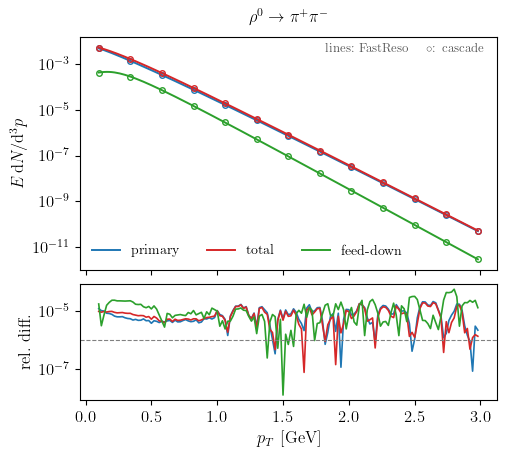

In [25]:
const TITLES = Dict(
    "rho_only.dat"      => raw"$\rho^0 \to \pi^+\pi^-$",
    "omega_only.dat"    => raw"$\omega \to \pi^+\pi^-\pi^0$",
    "small_thermal.dat" => raw"$\rho^0 + \omega$",
    "rho_chain.dat"     => raw"$\rho(1700) \to \rho^0\pi^-\pi^+ \to \pi^+\pi^-$")


function plot_fixture(fixture)
    entry = results[fixture]
    curves = (("primary", entry.reference.primary, entry.candidate.primary),
              ("total", entry.reference.total, entry.candidate.total),
              ("feed-down", entry.reference.total .- entry.reference.primary,
                            entry.candidate.total .- entry.candidate.primary))
    inside = findall(window)
    marks = inside[1:12:end]
    colou = ["tab:blue", "tab:red", "tab:green"]

    figure_handle, axes = subplots(2, 1, sharex = true,
        figsize = (pWidth * 1.7, pHeight * 2.0),
        gridspec_kw = Dict("height_ratios" => [2, 1], "hspace" => 0.08))
    upper, lower = axes[1], axes[2]

    for (index, (label, reference_values, candidate_values)) in enumerate(curves)
        colour = colou[index]
        # Only the reference line carries a label: six legend entries overflow
        # the axes, and the annotation says which is which.
        upper.plot(momenta[inside], reference_values[inside], "-", color = colour,
                   lw = 1.4, label = label)
        upper.plot(momenta[marks], candidate_values[marks], "o", color = colour,
                   ms = 4, mfc = "none", mew = 1.0)
        lower.plot(momenta[inside],
                   (abs.(candidate_values .- reference_values) ./
                    abs.(reference_values))[inside], "-", color = colour, lw = 1.2)
    end

    upper.set_yscale("log")
    upper.set_ylabel(raw"$E\,\mathrm{d}N/\mathrm{d}^3p$")
    upper.set_title(get(TITLES, fixture, fixture))
    upper.legend(frameon = false, ncol = 3, loc = "lower left")
    upper.text(0.97, 0.93, raw"lines: FastReso \quad $\circ$: cascade", ha = "right",
               transform = upper.transAxes, fontsize = 9, color = "0.35")
    #upper.grid(alpha = 0.25)

    lower.set_yscale("log")
    lower.set_xlabel(raw"$p_T$ [GeV]")
    lower.set_ylabel(raw"rel.\ diff.")
    lower.axhline(1e-6, color = "0.5", ls = "--", lw = 0.8)   # Fj print-precision floor
    #lower.grid(alpha = 0.25, which = "both")

    # tight_layout fights the gridspec hspace; set the margins explicitly.
    figure_handle.subplots_adjust(left = 0.17, right = 0.97, top = 0.92, bottom = 0.13)
    figure_handle
end

plot_fixture(FIXTURES[1])

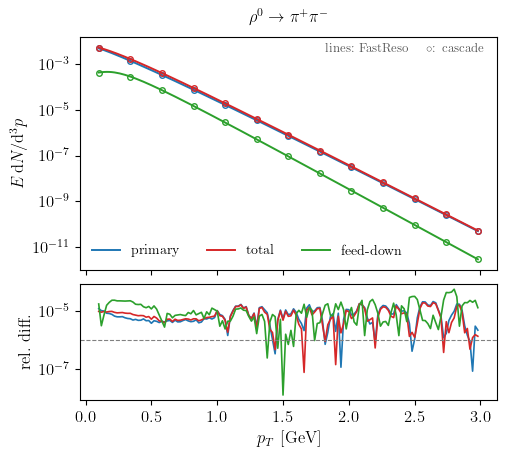

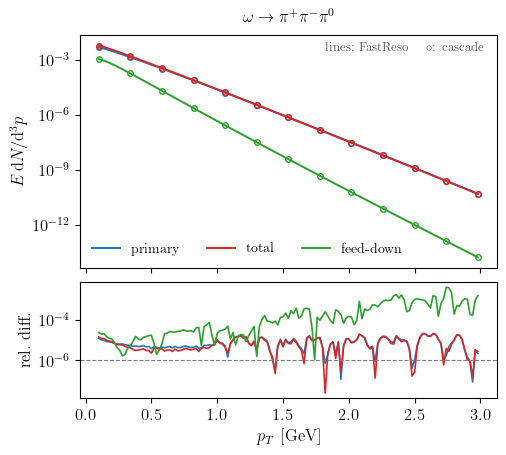

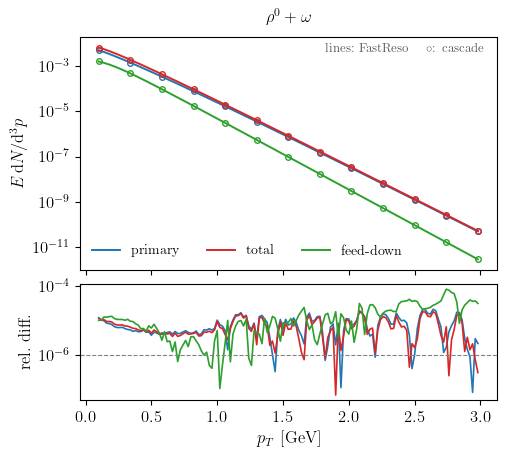

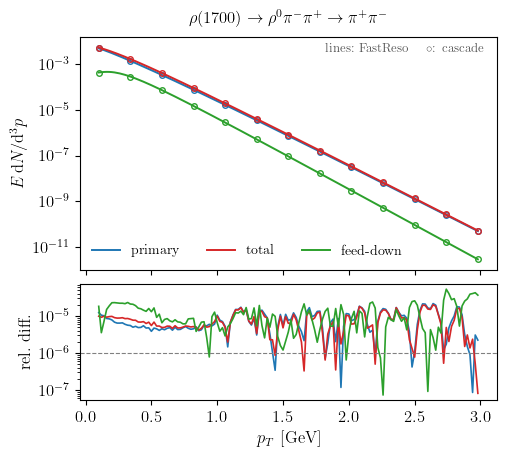

In [27]:
for fixture in FIXTURES[1:end]
    p=plot_fixture(fixture)
    display(p)
    savefig(string(fixture)*".pdf",bbox_inches="tight")  
end

## 8. Numbers

In [20]:
summary_rows = [
    let entry = results[fixture],
        pair = quantity === :feed ?
            (entry.reference.total .- entry.reference.primary,
             entry.candidate.total .- entry.candidate.primary) :
            (getfield(entry.reference, quantity), getfield(entry.candidate, quantity)),
        errors = (abs.(pair[2] .- pair[1]) ./ abs.(pair[1]))[window],
        worst_index = argmax(errors),
        # How much of the total this quantity is where the error peaks. A small
        # fraction means `total - primary` is a difference of close numbers, and
        # the relative error is inflated by roughly 1/fraction.
        fraction = abs(pair[1][window][worst_index]) /
                   abs(entry.reference.total[window][worst_index])
        (fixture, quantity, maximum(errors), sqrt(mean(abs2, errors)),
         momenta[window][worst_index], fraction)
    end
    for fixture in FIXTURES
    for quantity in (:primary, :total, :feed)
]

@printf("%-20s %10s %12s %12s %9s %12s\n",
        "fixture", "quantity", "max rel", "RMS rel", "worst p", "frac of tot")
for (fixture, quantity, maximum_error, rms_error, worst, fraction) in summary_rows
    @printf("%-20s %10s %12.3e %12.3e %9.3f %12.2e\n",
            fixture, quantity, maximum_error, rms_error, worst, fraction)
end
@printf("\nworst overall %.3e\n", maximum(row[3] for row in summary_rows))

fixture                quantity      max rel      RMS rel   worst p  frac of tot
rho_only.dat            primary    2.163e-05    9.277e-06     2.640     9.35e-01
rho_only.dat              total    1.976e-05    8.770e-06     2.640     1.00e+00
rho_only.dat               feed    5.779e-05    1.542e-05     2.800     6.01e-02
omega_only.dat          primary    2.163e-05    9.277e-06     2.640     9.99e-01
omega_only.dat            total    2.064e-05    8.882e-06     2.640     1.00e+00
omega_only.dat             feed    4.166e-03    7.186e-04     2.740     5.20e-04
small_thermal.dat       primary    2.163e-05    9.277e-06     2.640     9.35e-01
small_thermal.dat         total    1.953e-05    8.231e-06     2.080     1.00e+00
small_thermal.dat          feed    8.253e-05    2.120e-05     2.740     6.23e-02
rho_chain.dat           primary    2.163e-05    9.277e-06     2.640     9.35e-01
rho_chain.dat             total    2.006e-05    8.884e-06     2.640     1.00e+00
rho_chain.dat              f